# 01 - Data exploration

**Owner:** Member 1
**Task:** Describe the raw data of KuaiRand-Pure and KuaiRec: files, columns, example rows, feedback, users, videos, and how the unbiased part was collected. How these logs become the training data (positives, filtering, splits, checks) is in notebook 02.
**Inputs:** raw files under `data/`, src/data/ (file paths)
**Outputs:** results/01_kuairand_daily.png, results/01_kuairand_per_video.png, results/01_kuairec_watch_ratio.png

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import data

RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", None, "display.float_format", "{:,.3f}".format)

# 1. Summary of this section
## About Datasets
- Two datasets, both from Kuaishou (a short-video app). Each has two parts:
    - a biased part: videos the platform’s recommender chose to show. We use it to train, validate and test.
    - an unbiased part: videos the recommender did not choose. We use it only as a second test set.

- Since there are no star ratings. This kind of data is classified under implicit feedback. We will thus define the logs as a 0/1 user-item matrix. A cell is 1 if the user reacted positively to the video:
    - KuaiRand-Pure: a click.
    - KuaiRec: watched at least twice the video length.

## Datasets and Evaluation Protocol
- Split: for each user, a random 20% of their positives go to test. Then 10% of the remaining 80% go to validation.

- Main EDA finding: the biased test is full of popular videos, and on KuaiRand the unbiased test isn’t.
    - Share of test positives that fall on the top 10% most popular videos: 63% on KuaiRand’s biased test, 14% on its unbiased test.
    - A “recommend the most popular videos” baseline drops from Recall@20 0.114 to 0.007 on KuaiRand.
    - This gap is why the project exists.

- Metrics (defined in notebook 02, section 6):
    - Biased test: Recall@20 and NDCG@20. We rank all videos for each user and hide the ones they already interacted with in training and validation.
    - Unbiased test: we rank only the videos each user was actually shown and report GAUC and NDCG@5. Full-ranking Recall@20 and NDCG@20 are kept as a second row.

Note that our choices of which datasets to use are motivated by our research focus. While both datasets also provide user and video features (for example the user’s activity level and follower count, and the video’s category), we do not use them. BPR-MF and LightGCN are collaborative filtering models that learn only from the user-item interaction graph, and leaving side information out keeps the two models comparable, so that the graph is the only difference between them. Video length appears in the interaction logs and is used only to describe watch time and, for KuaiRec, to define a positive; it is never a model input.

# 2 EDA

## 2.1. EDA on KuaiRand-Pure

Interaction logs from Kuaishou, a short-video app (Gao et al., CIKM 2022). Each row is one **exposure**: a video was shown to a user, and the row records what the user did with it. Two things matter for this project:

- **Feedback is behaviour, not a rating.** There are several signals per exposure (click, like, follow, comment, forward, hate, long view) and the watch time.
- **Part of the exposure is random.** Normally the platform's own recommender decides what each user sees, so the log mostly contains videos the system already believed the user would like (*exposure bias*). For about two weeks the authors inserted **uniformly random videos** into the feed. Feedback on those videos is free of that bias, which lets us test a model on items the platform would not have chosen.

| File | Content | Used by us |
|---|---|---|
| `log_standard_4_08_to_4_21_pure.csv` | Exposures chosen by the platform recommender, 9 to 21 April 2022 (the file name says 8 April, the first row is 9 April) | yes (train, val, test) |
| `log_standard_4_22_to_5_08_pure.csv` | Same, 22 April to 8 May 2022 | yes (train, val, test) |
| `log_random_4_22_to_5_08_pure.csv` | Randomly exposed videos, 22 April to 8 May 2022 | yes (unbiased test set only) |
| `user_features_pure.csv` | Activity level, follower ranges, registration age, anonymous features | no |
| `video_features_basic_pure.csv` | Author, type, upload date, duration, tag | no |
| `video_features_statistic_pure.csv` | Platform-wide counters per video | no |

**Columns of a log row**

| Column | Meaning |
|---|---|
| `user_id`, `video_id` | Who was shown what |
| `date`, `hourmin`, `time_ms` | When |
| `is_click` | The user clicked the video (our positive) |
| `is_like`, `is_follow`, `is_comment`, `is_forward`, `is_hate` | Explicit reactions |
| `long_view` | The platform's long-view flag (watch time above its threshold) |
| `play_time_ms`, `duration_ms` | Watch time and video length |
| `profile_stay_time`, `comment_stay_time`, `is_profile_enter` | Time on the author's profile and in the comments |
| `is_rand` | 1 if the video was randomly exposed |
| `tab` | Part of the app where the exposure happened |

### What one row looks like

In [2]:
names = {"standard 04-09..04-21": data.KUAI_STANDARD[0], "standard 04-22..05-08": data.KUAI_STANDARD[1], "random 04-22..05-08": data.KUAI_RANDOM}
logs = pd.concat([pd.read_csv(os.path.join(data.KUAI_DIR, f)).assign(log=k) for k, f in names.items()], ignore_index=True)
logs["exposure"] = np.where(logs.is_rand == 1, "random", "standard")

logs.drop(columns=["log", "exposure"]).sample(8, random_state=0).reset_index(drop=True)

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
0,15518,5878,20220427,2000,1651060579872,0,0,0,0,0,0,0,1088,52400,0,0,0,1,1
1,25185,232,20220410,700,1649545931436,0,0,0,0,0,0,0,0,64166,0,0,0,0,1
2,24182,5603,20220417,900,1650158779979,1,0,0,0,0,0,1,25392,283783,0,0,0,0,1
3,12594,1331,20220504,1700,1651656562891,0,0,0,0,0,0,0,821,103380,0,0,0,1,1
4,15350,3647,20220416,1000,1650074472631,1,0,0,0,0,0,0,8163,45040,0,0,0,0,1
5,23453,3328,20220412,2300,1649775085447,0,0,0,0,0,0,0,0,380080,0,0,0,0,0
6,5102,3163,20220507,1700,1651916041781,0,0,0,0,0,0,0,1320,82566,0,0,0,1,1
7,4346,3844,20220412,1600,1649753327555,0,0,0,0,0,0,0,1286,114416,0,0,0,0,1


In [3]:
def overview(g):
    return pd.Series(dict(rows=len(g), users=g.user_id.nunique(), videos=g.video_id.nunique(),
                          first_day=str(g.date.min()), last_day=str(g.date.max()), random_share=g.is_rand.mean(),
                          rows_per_user=len(g) / g.user_id.nunique(), click_rate=g.is_click.mean()))

kuai_overview = pd.concat([logs.groupby("log", sort=False).apply(overview, include_groups=False),
                           overview(logs).to_frame("all logs").T])
kuai_overview

,rows,users,videos,first_day,last_day,random_share,rows_per_user,click_rate
standard 04-09..04-21,1141112,26210,7538,20220409,20220421,0.000,43.537,0.463
standard 04-22..05-08,295497,25877,6618,20220422,20220508,0.000,11.419,0.445
random 04-22..05-08,1186059,27285,7583,20220422,20220508,1.000,43.469,0.176
all logs,2622668,27285,7583,20220409,20220508,0.452,96.121,0.331


From the datasets given, we can see that the logs are split into two groups: standard and random. The standard group contains logs from April 4th to May 8th, while the random group contains logs from the same period but with random exposure. 

The logs contain information about the exposure, user, video, and feedback signals.  
- Exposure: Standard or Random
- User: User ID
- Video: Video ID
- Feedback signals: Click, Like, Follow, Comment, Forward

The `click rate` tells us that random videos are clicked less, because the recommender normally picks what users like. 

### Feedback signals
This is the `Rate per exposure`. 
- How often does each reaction happen? 
- Which one should be our positive?

Clicks are common; likes, follows, comments and forwards are rare. Every positive signal is much rarer on randomly exposed videos, because the platform recommender shows users what they tend to like and a random video usually is not that. The one negative signal, `is_hate`, goes the other way and is about twice as frequent on random videos.  

This helps us derive `is_click` as the positive.

In [4]:
SIGNALS = ["is_click", "long_view", "is_like", "is_follow", "is_comment", "is_forward", "is_profile_enter", "is_hate"]
signal_table = pd.DataFrame({"standard count": logs[logs.exposure == "standard"][SIGNALS].sum(),
                             "standard rate": logs[logs.exposure == "standard"][SIGNALS].mean(),
                             "random count": logs[logs.exposure == "random"][SIGNALS].sum(),
                             "random rate": logs[logs.exposure == "random"][SIGNALS].mean()})
signal_table["random / standard"] = signal_table["random rate"] / signal_table["standard rate"]
signal_table.style.format({"standard count": "{:,.0f}", "random count": "{:,.0f}", "standard rate": "{:.3%}",
                           "random rate": "{:.3%}", "random / standard": "{:.2f}"})

,standard count,standard rate,random count,random rate,random / standard
is_click,"660,342",45.965%,"208,934",17.616%,0.38
long_view,"476,724",33.184%,"100,769",8.496%,0.26
is_like,"26,546",1.848%,"5,691",0.480%,0.26
is_follow,"1,543",0.107%,310,0.026%,0.24
is_comment,"3,657",0.255%,411,0.035%,0.14
is_forward,"1,382",0.096%,402,0.034%,0.35
is_profile_enter,"34,496",2.401%,"6,597",0.556%,0.23
is_hate,710,0.049%,"1,351",0.114%,2.30


How the signals relate: of the exposures with one signal (row), the share that also has another (column).

In [5]:
core = ["is_click", "long_view", "is_like"]
pd.DataFrame({b: [logs.loc[logs[a] == 1, b].mean() for a in core] for b in core}, index=[f"given {a}" for a in core]).style.format("{:.1%}")

,is_click,long_view,is_like
given is_click,100.0%,66.2%,3.0%
given long_view,99.6%,100.0%,3.5%
given is_like,80.4%,62.2%,100.0%


### Watch time
Play time and video length in seconds. A play time of 0 means the video was shown but not played.

In [6]:
logs["play_s"], logs["duration_s"] = logs.play_time_ms / 1000, logs.duration_ms / 1000
watch = logs.groupby("exposure").agg(exposures=("play_s", "size"), not_played_share=("play_s", lambda s: (s == 0).mean()),
                                      median_play_s=("play_s", "median"), mean_play_s=("play_s", "mean"),
                                      median_duration_s=("duration_s", "median"))
watch["median_play_s_if_clicked"] = logs[logs.is_click == 1].groupby("exposure").play_s.median()
watch

,exposures,not_played_share,median_play_s,mean_play_s,median_duration_s,median_play_s_if_clicked
exposure,,,,,,
random,1186059,0.007,2.091,6.936,76.833,14.982
standard,1436609,0.132,4.904,22.893,70.200,27.569


### Exposures over time
The random log covers only the second period and sits on top of the standard feed.

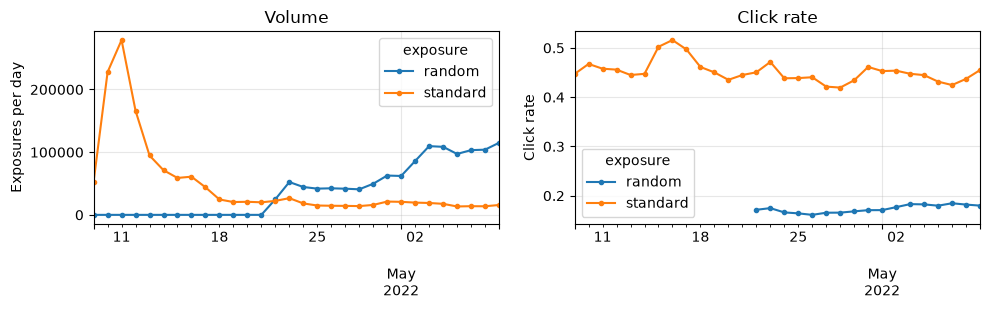

days  exposures  clicks  click_rate
period         exposure                                     
9-21 April     standard    13    1141112  528845       0.463
22 April-8 May standard    17     295497  131497       0.445
               random      17    1186059  208934       0.176

In [7]:
daily = logs.groupby(["date", "exposure"]).size().unstack(fill_value=0)
daily.index = pd.to_datetime(daily.index.astype(str), format="%Y%m%d")
clicks = logs.groupby(["date", "exposure"]).is_click.mean().unstack()
clicks.index = daily.index

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
daily.plot(ax=axes[0], marker="o", ms=3)
axes[0].set_ylabel("Exposures per day"); axes[0].set_title("Volume")
clicks.plot(ax=axes[1], marker="o", ms=3)
axes[1].set_ylabel("Click rate"); axes[1].set_title("Click rate")
for ax in axes:
    ax.set_xlabel(""); ax.grid(alpha=0.3); ax.legend(title="exposure")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_kuairand_daily.png"), dpi=200, metadata={"Software": None})
plt.show()

periods = logs.assign(period=np.where(logs.date <= 20220421, "9-21 April", "22 April-8 May")).groupby(["period", "exposure"], sort=False).agg(
    days=("date", "nunique"), exposures=("is_click", "size"), clicks=("is_click", "sum"), click_rate=("is_click", "mean"))
periods

We see that `random exposure` were collected only in the second period (22 April to 8 May). Their click rate stays at about 17% everyday against about 45% for recommender exposures. The gap reflects how the videos were chosen, not when they were shown. 

### Users and videos in the logs
Exposures and clicks per user and per video.

**per user**
- we group the rows by `user_id` and count the rows `exposure` and the `clicks`, separately for standard and random logs.

**per video**
-  we group by the `video_id` and count the rows `exposure` and the `clicks`, separately for standard and random logs.

In [8]:
def per_entity(col):
    rows = {}
    for exp, g in logs.groupby("exposure"):
        rows[(exp, "exposures")] = g.groupby(col).size().describe()
        rows[(exp, "clicks")] = g[g.is_click == 1].groupby(col).size().describe()
    return pd.DataFrame(rows).T.round(1)

print("Grouped by user_id")
display(per_entity("user_id"))

print("\nGrouped by video_id")
per_entity("video_id")

Grouped by user_id


count   mean    std    min    25%    50%    75%       max
random   exposures 27,285.000 43.500 63.900 10.000 14.000 22.000 45.000 1,580.000
         clicks    22,855.000  9.100 14.600  1.000  2.000  4.000 10.000   358.000
standard exposures 27,077.000 53.100 50.800  1.000 18.000 39.000 72.000   910.000
         clicks    26,591.000 24.800 22.900  1.000  8.000 18.000 35.000   237.000


Grouped by video_id


count    mean     std   min     25%     50%     75%        max
random   exposures 7,583.000 156.400  30.800 1.000 152.000 162.000 171.000    214.000
         clicks    7,485.000  27.900  14.500 1.000  17.000  26.000  36.000    106.000
standard exposures 7,551.000 190.300 437.800 1.000  21.000  57.000 177.000 10,424.000
         clicks    7,218.000  91.500 243.700 1.000   6.000  21.000  76.000  5,992.000

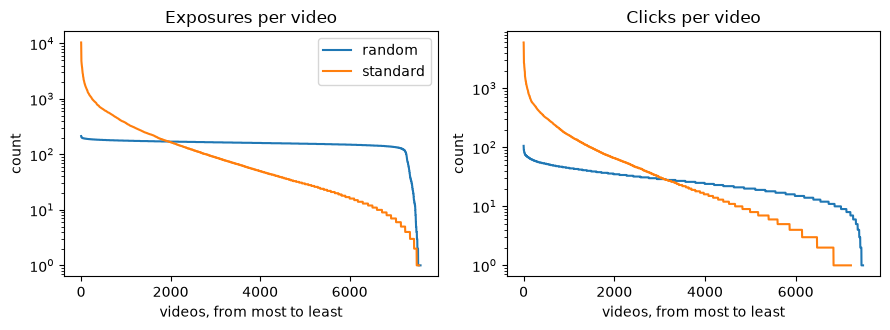

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (title, rows) in zip(axes, [("Exposures per video", logs), ("Clicks per video", logs[logs.is_click == 1])]):
    for exp, g in rows.groupby("exposure"):
        counts = np.sort(g.groupby("video_id").size().values)[::-1]
        ax.plot(np.arange(1, len(counts) + 1), counts, label=exp)
    ax.set(yscale="log", xlabel="videos, from most to least", ylabel="count", title=title)
axes[0].legend()
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_kuairand_per_video.png"), dpi=200, metadata={"Software": None})

In the `grouped by video_id` table, **standard exposure** is very uneven: the mean number of exposures per video (190) is more than three times the median (57), and the most-shown video was shown 10,424 times while a quarter of videos were shown 21 times or fewer. This is because the platform’s recommender chose these exposures, and it concentrates attention on a few videos. A video’s popularity in the standard log is therefore partly created by the recommender, not only by how much users like it.

**Random exposure**, by contrast, is almost uniform: half of all videos received between 152 and 171 exposures, and none received more than 214, which gives the nearly flat curve in the figure. Because every video had a similar chance of being shown, feedback on these videos is not shaped by the recommender’s choices, which is what we need for an unbiased test set.

How much the two kinds of exposure overlap. Most users appear in both logs, which is what makes the unbiased test set possible.

In [10]:
std, rnd = logs[logs.exposure == "standard"], logs[logs.exposure == "random"]
std_pos, rnd_pos = std[std.is_click == 1], rnd[rnd.is_click == 1]

def overlap(col):
    a, b, ap, bp = (set(x[col]) for x in (std, rnd, std_pos, rnd_pos))
    return {"in standard": len(a), "in random": len(b), "in both": len(a & b),
            "clicked in standard": len(ap), "clicked in random": len(bp), "clicked in both": len(ap & bp)}

pd.DataFrame({"users": overlap("user_id"), "videos": overlap("video_id")}).T

,in standard,in random,in both,clicked in standard,clicked in random,clicked in both
users,27077,27285,27077,26591,22855,22335
videos,7551,7583,7551,7218,7485,7124


**Overlap between the two logs**

- **Every standard user and every standard video also appears in the random log** (27,077 users and 7,551 videos). This is what makes the unbiased test possible: the same people and the same catalogue, but a different way of choosing what they saw.
- **The random log is slightly larger**. It contains 208 users and 32 videos that never appear in the standard log. They have no training data, so they cannot be used.
- **Not everyone clicks a random video**. 22,335 users clicked in both logs. This is the most users the unbiased test could possibly cover.
- **Some videos are clicked only under random exposure**. 361 videos were clicked in the random log but never in the standard log. They are not in our item set, so their random clicks are dropped. These are videos users liked but the recommender barely showed them, so they are a small loss of exactly the kind of feedback the unbiased test is meant to capture.

**Final dataset size (seed 0)** from this KuaiRand-Pure we  will be using in our later experiments.
- **Users:** 25,689. 26,591 users clicked at least one standard video. We drop the 902 users with only one click, because a user needs at least one positive in training and one in test.
- **Items:** 7,218, exactly the number of videos with at least one standard click. Positives come only from clicks, so a video nobody clicked in the standard log never enters our training graph. Dropping the 902 one-click users removes no video.
- **Interactions:** 466,490 train, 54,223 validation and 131,436 test positives. The density is 466,490 / (25,689 × 7,218) = 0.25%.
- **Unbiased test:** 194,539 positives from 21,515 users. A random-log click is kept only if:
    - its user and video are both in our dataset, and
    - the same user did not also click that video in the standard log, since that pair is already a known positive in training or the biased test.

--- 

## 2.2. EDA on KuaiRec

Also from Kuaishou, collected 5 July to 5 September 2020 (Gao et al., CIKM 2022). It has two parts:

- **Big matrix:** ordinary logs. Videos reached users through the platform recommender, so they carry the same exposure bias as KuaiRand's standard logs.
- **Small matrix:** for 1,411 users and a fixed block of 3,327 videos, the authors exposed *every* video to *every* user (99.6% of the pairs are filled; the rest are videos a user had blocked). Here nothing is missing because of the recommender, so it is an unbiased test set of a different kind from KuaiRand's random exposure.

There is no click or like. Each row is a play, and the feedback is the **watch ratio** = play time / video length. It can exceed 1 when the user replays the video. We call a pair positive when the user watched at least twice the video length (`watch_ratio >= 2`) in at least one play.

| File (inside `KuaiRec.zip`) | Content | Used by us |
|---|---|---|
| `big_matrix.csv` | 12.5M plays, 7,176 users, 10,728 videos | yes (train, val, test) |
| `small_matrix.csv` | 4.7M plays, 1,411 users x 3,327 videos | yes (unbiased test set only) |
| `user_features.csv`, `item_categories.csv`, `item_daily_features.csv`, `kuairec_caption_category.csv`, `social_network.csv` | Side information | no |

**Columns of a play**

| Column | Meaning |
|---|---|
| `user_id`, `video_id` | Who watched what |
| `play_duration`, `video_duration` | Watch time and video length, in milliseconds |
| `watch_ratio` | play_duration / video_duration |
| `time`, `date`, `timestamp` | When |

The loader reads the two CSV files straight from the zip archive, so it does not need to be extracted.

In [11]:
cols = ["user_id", "video_id", "play_duration", "video_duration", "date", "watch_ratio"]
types = {"user_id": "int32", "video_id": "int32", "play_duration": "int64", "video_duration": "int64", "watch_ratio": "float32"}
with zipfile.ZipFile(data.KUAIREC_ZIP) as z:
    rec = {m: pd.read_csv(z.open(data.KUAIREC_FILES + f"{m}_matrix.csv"), usecols=cols, dtype=types) for m in ("big", "small")}
for m in rec.values():
    m["date"] = m.date.fillna(0).astype("int32")

def matrix_overview(m):
    pairs = len(m.drop_duplicates(["user_id", "video_id"]))
    users, videos = m.user_id.nunique(), m.video_id.nunique()
    return pd.Series(dict(plays=len(m), unique_pairs=pairs, repeated_plays=len(m) - pairs, users=users, videos=videos,
                          density=pairs / (users * videos), first_day=str(m.date[m.date > 0].min()), last_day=str(m.date.max())))

pd.DataFrame({k: matrix_overview(m) for k, m in rec.items()}).T

,plays,unique_pairs,repeated_plays,users,videos,density,first_day,last_day
big,12530806,10300969,2229837,7176,10728,0.134,20200705,20200905
small,4676570,4676570,0,1411,3327,0.996,20200705,20200905


### What one row looks like

In [12]:
rec["big"].sample(8, random_state=0).reset_index(drop=True)

,user_id,video_id,play_duration,video_duration,date,watch_ratio
0,6188,571,4670,17234,20200803,0.271
1,336,10506,6196,7488,20200829,0.827
2,4665,171,6879,5217,20200706,1.319
3,4883,171,6507,5217,20200802,1.247
4,2014,1986,12484,9467,20200711,1.319
5,6982,5262,4872,7908,20200706,0.616
6,2987,4411,8334,7267,20200829,1.147
7,7171,71,3402,13414,20200712,0.254


### Watch ratio
Quantiles of the watch ratio per play, then how many plays and unique pairs pass each threshold.

In [13]:
display(pd.DataFrame({k: m.watch_ratio.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]) for k, m in rec.items()}).T)

rows = []
for t in [0.5, 1.0, 1.5, 2.0, 3.0]:
    for k, m in rec.items():
        p = m[m.watch_ratio >= t].drop_duplicates(["user_id", "video_id"])
        rows.append(dict(threshold=t, matrix=k, share_of_plays=(m.watch_ratio >= t).mean(), positive_pairs=len(p),
                         users=p.user_id.nunique(), videos=p.video_id.nunique()))
pd.DataFrame(rows).set_index(["threshold", "matrix"])

,0.100,0.250,0.500,0.750,0.900,0.990
big,0.113,0.315,0.723,1.178,1.784,4.793
small,0.197,0.468,0.769,1.121,1.559,3.585


share_of_plays  positive_pairs  users  videos
threshold matrix                                               
0.500     big              0.641         6885007   7176   10727
          small            0.727         3401473   1411    3327
1.000     big              0.338         3731826   7176   10719
          small            0.324         1515050   1411    3317
1.500     big              0.151         1689080   7175   10674
          small            0.112          524156   1411    3298
2.000     big              0.075          846414   7175   10611
          small            0.046          217229   1411    3276
3.000     big              0.027          312145   6973    8833
          small            0.015           71802   1392    3221

### Watch ratio depends on video length
Replaying a short video is easy, so a watch-ratio threshold favours short videos. This is a property of the positive definition, not of the user, and it is worth stating in the report.

In [14]:
big = rec["big"]
length = pd.cut(big.video_duration / 1000, [0, 10, 20, 30, 60, 1e9], labels=["<10 s", "10-20 s", "20-30 s", "30-60 s", ">60 s"])
by_len = big.groupby(length, observed=True).agg(plays=("watch_ratio", "size"), median_ratio=("watch_ratio", "median"),
                                                share_ratio_ge_2=("watch_ratio", lambda r: (r >= 2).mean()))
by_len["share_of_plays"] = by_len.plays / by_len.plays.sum()
by_len

,plays,median_ratio,share_ratio_ge_2,share_of_plays
video_duration,,,,
<10 s,6814719,0.990,0.110,0.544
10-20 s,4198182,0.593,0.042,0.335
20-30 s,516188,0.283,0.015,0.041
30-60 s,683472,0.156,0.006,0.055
>60 s,318245,0.061,0.002,0.025


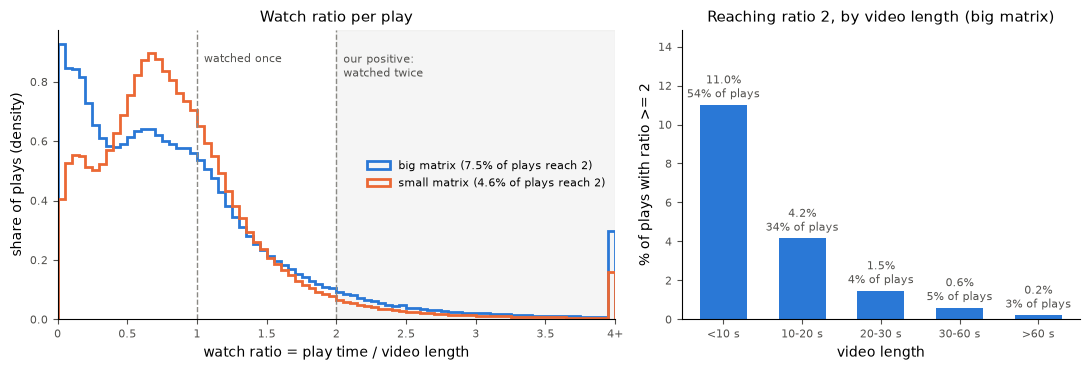

In [15]:
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#52514e", "#8a8984"
THRESHOLD = 2.0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1.4, 1]))

bins = np.arange(0, 4.05, 0.05)
for (name, m), color in zip(rec.items(), (BLUE, ORANGE)):
    share = (m.watch_ratio >= THRESHOLD).mean()
    ax1.hist(m.watch_ratio.clip(upper=4), bins=bins, density=True, histtype="step", lw=2, color=color,
             label=f"{name} matrix ({share:.1%} of plays reach {THRESHOLD:g})")
for x, text in [(1, "watched once"), (THRESHOLD, "our positive:\nwatched twice")]:
    ax1.axvline(x, color=MUTED, ls="--", lw=1)
    ax1.text(x + 0.05, ax1.get_ylim()[1] * 0.92, text, color=INK, fontsize=8, va="top")
ax1.axvspan(THRESHOLD, 4, color=MUTED, alpha=0.08)
ax1.set(xlim=(0, 4), xlabel="watch ratio = play time / video length", ylabel="share of plays (density)",
        title="Watch ratio per play")
ax1.set_xticks(np.arange(0, 4.5, 0.5), [f"{x:g}" for x in np.arange(0, 4, 0.5)] + ["4+"])
ax1.legend(frameon=False, fontsize=8, loc="center right")

big = rec["big"]
length = pd.cut(big.video_duration / 1000, [0, 10, 20, 30, 60, 1e9], labels=["<10 s", "10-20 s", "20-30 s", "30-60 s", ">60 s"])
by_len = big.groupby(length, observed=True).watch_ratio.agg(share=lambda r: (r >= THRESHOLD).mean(), plays="size")
bars = ax2.bar(by_len.index.astype(str), by_len.share * 100, color=BLUE, width=0.6)
for b, (share, plays) in zip(bars, by_len.itertuples(index=False)):
    ax2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, f"{share:.1%}\n{plays / len(big):.0%} of plays",
             ha="center", va="bottom", fontsize=8, color=INK)
ax2.set(ylim=(0, by_len.share.max() * 135), xlabel="video length", ylabel=f"% of plays with ratio >= {THRESHOLD:g}",
        title="Reaching ratio 2, by video length (big matrix)")

for ax in (ax1, ax2):
    ax.title.set_fontsize(11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=INK, labelsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "01_kuairec_watch_ratio.png"), dpi=200, metadata={"Software": None})
plt.show()

**How to read the figure.** Left: how the plays of each matrix spread over the watch ratio (each curve has area 1, so the shapes compare despite the different sizes). The dashed lines mark 1 (watched once) and 2 (our positive); plays at 4 or above are grouped in the last bin.

- Most plays end before the video ends (ratio below 1). Above 1 the user replayed the video; the app loops it automatically.
- Fewer small-matrix plays reach 2 (4.6% against 7.5%). In the big matrix the recommender chose videos it expected the user to like; in the small matrix every user saw every block video, suited or not. Feedback looks better in biased logs because of how the videos were chosen.
- Right: the share of plays that reach ratio 2 falls from 11% for videos under 10 s to 0.2% for videos over 60 s. Replaying a 7 s video costs 14 s, a 60 s video two minutes, so the positive definition favours short videos. All models see the same positives, so the comparison stays fair, but this is a limitation of KuaiRec's positives.

### Users and videos
Plays and positives (`watch_ratio >= 2`) per user and per video in each matrix.

In [16]:
def per_entity_rec(col):
    out = {}
    for k, m in rec.items():
        out[(k, "plays")] = m.groupby(col).size().describe()
        out[(k, "positives")] = m[m.watch_ratio >= 2].drop_duplicates(["user_id", "video_id"]).groupby(col).size().describe()
    return pd.DataFrame(out).T.round(1)

display(per_entity_rec("user_id"))
per_entity_rec("video_id")

count      mean     std       min       25%       50%       75%        max
big   plays     7,176.000 1,746.200 991.800   100.000   883.000 1,846.500 2,461.000 16,015.000
      positives 7,175.000   118.000 101.900     1.000    43.000    88.000   162.000  1,002.000
small plays     1,411.000 3,314.400   7.000 3,295.000 3,309.000 3,315.000 3,320.000  3,327.000
      positives 1,411.000   154.000 152.600     6.000    44.000    95.000   222.500    994.000

count      mean       std       min       25%       50%       75%        max
big   plays     10,728.000 1,168.000 1,599.900     1.000    38.000   243.000 2,142.500 27,615.000
      positives 10,611.000    79.800   158.000     1.000     3.000    13.000    94.000  2,559.000
small plays      3,327.000 1,405.600    15.700 1,315.000 1,410.000 1,411.000 1,411.000  1,411.000
      positives  3,276.000    66.300    85.800     1.000    27.000    44.000    78.000  1,023.000

### How the small matrix relates to the big one
Every small-matrix user and video also appears in the big matrix, but no (user, video) pair is in both, so training on the big matrix and testing on the small one cannot leak. The block videos are not a random sample of the catalogue: they are among the more popular videos of the big matrix.

In [17]:
small = rec["small"]
big_plays = big.groupby("video_id").size()
top10 = set(big_plays.sort_values(ascending=False).index[: len(big_plays) // 10])
block = small.video_id.unique()
big_pairs = pd.MultiIndex.from_frame(big[["user_id", "video_id"]].drop_duplicates())
small_pairs = pd.MultiIndex.from_frame(small[["user_id", "video_id"]].drop_duplicates())
pd.Series({"small users in big": f"{np.isin(small.user_id.unique(), big.user_id.unique()).sum():,} of {small.user_id.nunique():,}",
           "small videos in big": f"{np.isin(block, big.video_id.unique()).sum():,} of {len(block):,}",
           "pairs in both matrices": f"{len(big_pairs.intersection(small_pairs)):,}",
           "block videos among the top 10% of big-matrix videos (by plays)": f"{np.mean([v in top10 for v in block]):.1%}",
           "median big-matrix plays, block videos": f"{big_plays.reindex(block).median():,.0f}",
           "median big-matrix plays, all videos": f"{big_plays.median():,.0f}"}).to_frame("value")

,value
small users in big,"1,411 of 1,411"
small videos in big,"3,327 of 3,327"
pairs in both matrices,0
block videos among the top 10% of big-matrix videos (by plays),30.7%
"median big-matrix plays, block videos","2,832"
"median big-matrix plays, all videos",243


### Plays over time

In [18]:
weekly = pd.concat({k: m[m.date > 0].assign(week=pd.to_datetime(m.date[m.date > 0].astype(str), format="%Y%m%d").dt.to_period("W").astype(str))
                       .groupby("week").agg(plays=("watch_ratio", "size"), users=("user_id", "nunique"), share_ratio_ge_2=("watch_ratio", lambda r: (r >= 2).mean()))
                    for k, m in rec.items()}, axis=1).sort_index()
weekly

big                              small                       
                              plays     users share_ratio_ge_2   plays users share_ratio_ge_2
week                                                                                         
2020-06-29/2020-07-05   188,387.000 6,728.000            0.094   28335  1351            0.066
2020-07-06/2020-07-12 2,003,967.000 7,040.000            0.088  431682  1407            0.055
2020-07-13/2020-07-19           NaN       NaN              NaN  612593  1411            0.052
2020-07-20/2020-07-26           NaN       NaN              NaN  605475  1411            0.048
2020-07-27/2020-08-02 1,284,415.000 7,054.000            0.078  772838  1411            0.044
2020-08-03/2020-08-09 5,146,001.000 7,159.000            0.069  776142  1411            0.039
2020-08-10/2020-08-16   577,102.000 6,552.000            0.066  525102  1410            0.042
2020-08-17/2020-08-23           NaN       NaN              NaN  419346  1411            0.045
2020-08-24/2020-08-30 1,510,371.000 6,929.000            0.074  244777  1411            0.054
2020-08-31/2020-09-06 1,820,563.000 6,899.000            0.075   78288  1411            0.055

**Final dataset size (seed 0)** from this KuaiRec we will be using in our later experiments.
- **Users:** 7,173. The big matrix has 7,176 users; 7,175 of them have at least one positive (a play with watch ratio 2 or more), and one user has none. We drop the 2 users with only one positive, because a user needs at least one positive in training and one in test.
- **Items:** 10,611, exactly the number of videos with at least one positive in the big matrix. The other 117 of the 10,728 videos were played but never reached watch ratio 2, so they never enter our training graph. Dropping the 2 one-positive users removes no video.
- **Interactions:** 609,375 train, 67,773 validation and 169,264 test positives. The density is 609,375 / (7,173 × 10,611) = 0.80%, about three times KuaiRand-Pure's, with 85 training positives per user against 18.
- **Unbiased test:** 216,727 positives from 1,408 users. A small-matrix positive is kept only if:
    - its user and video are both in our dataset. The 3 users missing from our graph (the user without any positive and the 2 one-positive users) all belong to the small matrix, which removes 386 positives; one block video has no positive in the big matrix, which removes another 116. So 1,408 of the 1,411 users and 3,326 of the 3,327 block videos remain.
    - unlike KuaiRand-Pure, no pair has to be removed for being a known positive, because no (user, video) pair appears in both matrices.
- **Ranking on the unbiased test:** only among the 3,326 block videos, since we only know the truth for those. Users have about 154 unbiased positives each but we recommend 20, so the best possible Recall@20 is about 0.32.

The raw logs continue in notebook 02, which turns them into the datasets the models use.